In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/lthnhcng/imdb-dataset/IMDB Dataset.csv


# 11. Experiment 1 — Dataset inspection

In [ ]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder.master(
    "local[*]"
).appName("Word2VecExperiment").config("spark.driver.memory", "8g").getOrCreate()

In [29]:
# Load the IMDb dataset
path = "/kaggle/input/datasets/lthnhcng/imdb-dataset/IMDB Dataset.csv"
data = spark.read.csv(path, header=True, multiLine=True, escape='"')
data.show(5)

+--------------------+---------+
|              review|sentiment|
+--------------------+---------+
|One of the other ...| positive|
|A wonderful littl...| positive|
|I thought this wa...| positive|
|Basically there's...| negative|
|Petter Mattei's "...| positive|
+--------------------+---------+
only showing top 5 rows


In [43]:
from pyspark.sql import functions as F

text_col = "review"
label_col = "sentiment"

# 1. In thông tin cơ bản (Đoạn mã hiện tại của bạn)
print("Number of sample: ", data.count())
print("Number of classes: ", data.select(label_col).distinct().count())
print("Classes distribution:")
data.groupBy(label_col).agg(F.count("*").alias("total_reviews")).show()

# 2. Tạo cột phụ tính độ dài chuỗi (đếm số từ bằng cách tách khoảng trắng)
# Nếu tính theo số ký tự, bạn chỉ cần thay bằng: F.length(F.col(text_col))
data_with_len = data.withColumn("seq_length", F.size(F.split(F.col(text_col), "\\s+")))

# 3. Tính toán các chỉ số: Minimum, Mean, Maximum sequence length
print("--- Sequence Length Statistics ---")
stats = data_with_len.select(
    F.min("seq_length").alias("min_len"),
    F.mean("seq_length").alias("mean_len"),
    F.max("seq_length").alias("max_len")
).collect()[0]

print(f"Minimum sequence length: {stats['min_len']}")
print(f"Mean sequence length: {stats['mean_len']:.2f}")
print(f"Maximum sequence length: {stats['max_len']}")

# 4. Tính Median sequence length (Trung vị)
# Sử dụng hàm approxQuantile (0.5 tương ứng với vị trí 50% - Median)
median_len = data_with_len.approxQuantile("seq_length", [0.5], 0.001)[0]
print(f"Median sequence length: {median_len}")

# 5. Thống kê trùng lặp (Duplicate documents)
total_count = data.count()
distinct_text_count = data.select(text_col).distinct().count()
duplicate_count = total_count - distinct_text_count
print(f"\nDuplicate documents (Dựa trên nội dung text): {duplicate_count}")

# 6. Thống kê dữ liệu khuyết thiếu (Missing text & Missing labels)
# Kiểm tra cả trường hợp giá trị là NULL hoặc chuỗi rỗng/khoảng trắng
missing_stats = data.select(
    F.sum(F.when(F.col(text_col).isNull() | (F.trim(F.col(text_col)) == ""), 1).otherwise(0)).alias("missing_text"),
    F.sum(F.when(F.col(label_col).isNull() | (F.trim(F.col(label_col)) == ""), 1).otherwise(0)).alias("missing_labels")
).collect()[0]

print(f"Missing text: {missing_stats['missing_text']}")
print(f"Missing labels: {missing_stats['missing_labels']}")


Number of sample:  50000
Number of classes:  2
Classes distribution:
+---------+-------------+
|sentiment|total_reviews|
+---------+-------------+
| positive|        25000|
| negative|        25000|
+---------+-------------+

--- Sequence Length Statistics ---


Minimum sequence length: 4
Mean sequence length: 231.15
Maximum sequence length: 2470


Median sequence length: 173.0



Duplicate documents (Dựa trên nội dung text): 418


Missing text: 0
Missing labels: 0


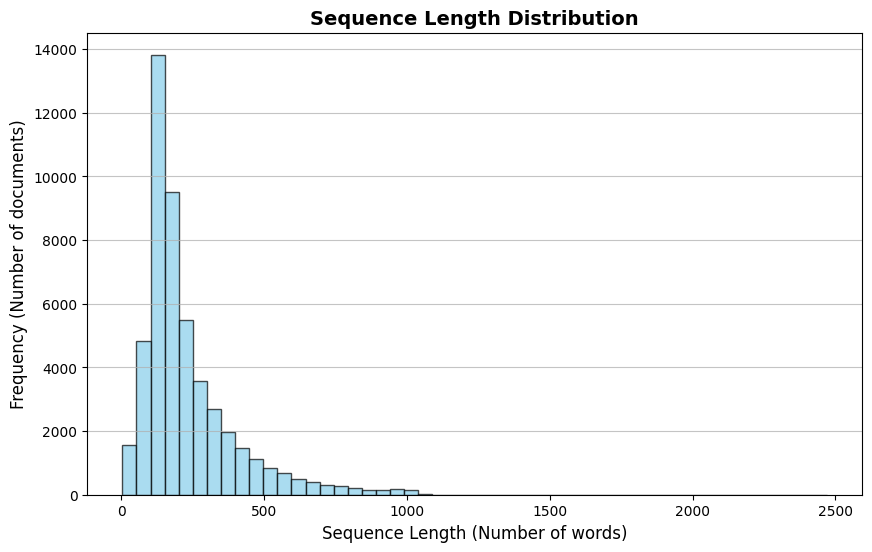

In [45]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# 1. Tạo cột tính độ dài chuỗi (số từ) nếu chưa có
data_with_len = data.withColumn("seq_length", F.size(F.split(F.col("review"), "\\s+")))

# 2. Lấy danh sách độ dài về Driver dưới dạng Pandas/List để vẽ (Nếu dữ liệu cực lớn, xem lưu ý phía dưới)
# Cách 1: Dành cho tập dữ liệu vừa phải (vài triệu dòng trở xuống)
pdf = data_with_len.select("seq_length").toPandas()

# 3. Vẽ biểu đồ Histogram
plt.figure(figsize=(10, 6))
# Bins=50 chia khoảng độ dài chuỗi thành 50 cột để dễ quan sát phân phối
plt.hist(pdf['seq_length'], bins=50, color='skyblue', edgecolor='black', alpha=0.7)

plt.title('Sequence Length Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Sequence Length (Number of words)', fontsize=12)
plt.ylabel('Frequency (Number of documents)', fontsize=12)
plt.grid(axis='y', alpha=0.75)

# Hiển thị biểu đồ
plt.show()

## Chọn MaxLength

Việc lựa chọn `max_length` (độ dài chuỗi tối đa) là sự cân bằng giữa **độ chính xác của mô hình** (giữ đủ ngữ nghĩa văn bản) và **hiệu năng phần cứng** (tốc độ xử lý và bộ nhớ RAM/VRAM). Chúng ta cần dựa trên 3 thông tin cốt lõi sau:

### 1. Chỉ số Phân vị (Percentiles) của tập dữ liệu
* **Phương pháp:** Phân tích các mốc phân vị quan trọng như **95th percentile** hoặc **99th percentile** từ thống kê dữ liệu thực tế.
* **Ý nghĩa:** Nếu chỉ số phân vị thứ 95 (95th percentile) của độ dài văn bản là `120`, điều đó có nghĩa là **95% số văn bản trong toàn bộ tập dữ liệu có độ dài từ 120 từ trở xuống**.
* **Tiêu chí chọn:** Chọn `max_length` tiệm cận mốc này (ví dụ: 120) đảm bảo mô hình giữ được trọn vẹn thông tin của 95% dữ liệu thực tế, chỉ chấp nhận cắt bỏ (truncate) phần đuôi quá dài của 5% số tài liệu cá biệt (outliers).

### 2. Hình dáng biểu đồ Phân phối (Histogram)
* **Hiện tượng:** Dữ liệu văn bản NLP thông thường có dạng **lệch phải nặng (Right-skewed / Long tail)**. Nghĩa là đại đa số văn bản rất ngắn, nhưng có một vài văn bản có độ dài đột biến cực lớn.
* **Hệ quả nếu chọn sai:** Nếu chọn `max_length` bằng với độ dài lớn nhất (Maximum length), mô hình sẽ phải đệm thêm rất nhiều ký tự trống (`[PAD]`) cho toàn bộ các văn bản ngắn còn lại. Điều này làm lãng phí bộ nhớ và giảm tốc độ huấn luyện một cách vô ích.
* **Tiêu chí chọn:** Chọn `max_length` ngay tại **điểm gãy của đồ thị** (vị trí mà tần suất bắt đầu giảm sâu và kéo dài thành đuôi mỏng) để tối ưu hóa không gian tính toán.

### 3. Giới hạn vật lý của kiến trúc mô hình (Cơ chế Attention)
* **Đặc tính:** Các mô hình Transformer (như BERT, RoBERTa, GPT) sử dụng cơ chế Self-Attention có chi phí tính toán tăng theo **bình phương độ dài chuỗi** (O(N²)). Bản thân các mô hình này cũng có giới hạn trần cố định (thường là **512 tokens**).
* **Tiêu chí chọn:** Giá trị `max_length` được chọn bắt buộc không được vượt quá giới hạn cứng của mô hình (ví dụ: 512). Nếu dữ liệu thực tế quá dài vượt ngưỡng này, ta phải chấp nhận cắt ngắn ở mức 512 hoặc chuyển sang các kiến trúc chuyên dụng cho văn bản dài (như Longformer, BigBird).

---
**KẾT LUẬN:** 
Lựa chọn `max_length` khoa học là chọn giá trị **bao phủ từ 95% đến 99% lượng dữ liệu thực tế** (dựa trên chỉ số Quantile và biểu đồ Histogram), đồng thời **nằm trong giới hạn thiết kế của mô hình**. Cách làm này giúp giữ lại tối đa ngữ nghĩa văn bản mà không làm lãng phí tài nguyên tính toán cho các token đệm `[PAD]`.

# 13. Experiment 2 — Padding và truncation
Ở experiemnt 2 ta có thể tận dụng kết quả của experiment 5 như sau


## Result

### Kết quả thực nghiệm

| max_length | Tokens retained | Reviews truncated | Training time (s) | Val Loss | F1 |
|---:|---:|---:|---:|---:|---:|
| 50  | 21.49% | 97.54% | 46.35 | 0.6298 | 0.6953 |
| 100 | 41.52% | 87.76% | 59.07 | 0.6120 | 0.6814 |
| 200 | **68.49%** | **40.98%** | 82.99 | **0.5816** | **0.7524** |

Peak GPU memory gần như không thay đổi:

| max_length | Peak GPU |
|---:|---:|
| 50 | 456.60 MB |
| 100 | 456.61 MB |
| 200 | 456.64 MB |

---

### Tăng `max_length` có luôn cải thiện performance không?

**Không.**

Trong thí nghiệm:

```text
50 → 100:
F1 0.6953 → 0.6814  ↓

100 → 200:
F1 0.6814 → 0.7524  ↑
```

Do đó, performance không tăng đơn điệu theo `max_length`.

### Nếu `max_length` quá nhỏ, loại thông tin nào có thể bị mất?

Các token nằm ngoài giới hạn sẽ bị truncate, có thể bao gồm:

- Từ khóa sentiment.
- Từ phủ định.
- Context của câu.
- Thông tin quan trọng nằm ở giữa hoặc cuối review.

Đặc biệt, `max_length = 50` chỉ giữ lại **21.49% token** và có **97.54% review bị truncate**, cho thấy nguy cơ mất thông tin là rất lớn.

### Kết luận

> **Không nên chọn `max_length` quá nhỏ vì có thể làm mất thông tin quan trọng. Tuy nhiên, tăng `max_length` cũng không đảm bảo performance luôn tăng và sẽ làm tăng computational cost. Trong thí nghiệm này, `max_length = 200` là lựa chọn tốt nhất vì đạt F1 cao nhất (0.7524) và validation loss thấp nhất (0.5816), dù có training time lớn nhất (82.99s).**

# 15. Experiment 3 — Baseline (TF-IDF + Logistic Regression)

In [27]:
path = "/kaggle/input/datasets/lthnhcng/imdb-dataset/IMDB Dataset.csv"

In [5]:
data = spark.read.csv(path, header=True, multiLine=True, escape='"')
data.show(5)

+--------------------+---------+
|              review|sentiment|
+--------------------+---------+
|One of the other ...| positive|
|A wonderful littl...| positive|
|I thought this wa...| positive|
|Basically there's...| negative|
|Petter Mattei's "...| positive|
+--------------------+---------+
only showing top 5 rows


In [6]:
from pyspark.ml.feature import RegexTokenizer
from pyspark.ml.feature import StringIndexer

tokenizer = RegexTokenizer(
    inputCol="review",
    outputCol="words",
    pattern =r"[\S.,?!:;\"/)(><\\]+",
    gaps=False
)

words_df = tokenizer.transform(data)
words_df.show(5)

indexer = StringIndexer(
    inputCol = "sentiment",
    outputCol = "label",
    handleInvalid="skip"
)

indexer_model = indexer.fit(words_df)

df_index = indexer_model.transform(words_df)

df_index.show(5)

+--------------------+---------+--------------------+
|              review|sentiment|               words|
+--------------------+---------+--------------------+
|One of the other ...| positive|[one, of, the, ot...|
|A wonderful littl...| positive|[a, wonderful, li...|
|I thought this wa...| positive|[i, thought, this...|
|Basically there's...| negative|[basically, there...|
|Petter Mattei's "...| positive|[petter, mattei's...|
+--------------------+---------+--------------------+
only showing top 5 rows


+--------------------+---------+--------------------+-----+
|              review|sentiment|               words|label|
+--------------------+---------+--------------------+-----+
|One of the other ...| positive|[one, of, the, ot...|  1.0|
|A wonderful littl...| positive|[a, wonderful, li...|  1.0|
|I thought this wa...| positive|[i, thought, this...|  1.0|
|Basically there's...| negative|[basically, there...|  0.0|
|Petter Mattei's "...| positive|[petter, mattei's...|  1.0|
+--------------------+---------+--------------------+-----+
only showing top 5 rows


In [7]:
train_set, validation_set, test_set = df_index.randomSplit(
    [0.6, 0.2, 0.2],
    seed = 2026
)

## Base line

In [8]:
import time
from pyspark.ml.feature import CountVectorizer, IDF
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml import Pipeline

# khai bao countervectozier
cv = CountVectorizer(inputCol="words", outputCol="tf", vocabSize=1000, minDF=2.0)

idf = IDF(inputCol="tf", outputCol="tfidf")

# khai bao model logistic regression
lr = LogisticRegression(
    featuresCol = "tfidf",
    labelCol="label",
    maxIter=10
)

pipeline = Pipeline(stages=[cv, idf, lr])

print("Trainning TF-IDF + Logistic Regression")
start_time = time.time()
baseline_model = pipeline.fit(train_set)
baseline_training_time = time.time() - start_time

print(f"Training time: {baseline_training_time:.2f} seconds")

Trainning TF-IDF + Logistic Regression


Training time: 35.66 seconds


In [9]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# get vocab size
cv_model = baseline_model.stages[0]
vocab_size_baseline = len(cv_model.vocabulary)
print(f"Vocabulary size: {vocab_size_baseline}")

# Prediction on validation set
print("\nEvaluation on Validation Set")
val_predictions = baseline_model.transform(validation_set)
val_accuracy = val_predictions.filter(
    (F.col("prediction") == F.col("label"))
).count() / val_predictions.count()

# Precision, Recall, F1
evaluator_multi = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedPrecision"
)
val_precision = evaluator_multi.evaluate(val_predictions)

evaluator_multi.setMetricName("weightedRecall")
val_recall = evaluator_multi.evaluate(val_predictions)

evaluator_multi.setMetricName("f1")
val_f1 = evaluator_multi.evaluate(val_predictions)

print(f"\n{'Model':<20} {'Accuracy':<12} {'Precision':<12} {'Recall':<12} {'F1':<12}")
print("-" * 68)
print(f"{'TF-IDF + LR':<20} {val_accuracy:<12.4f} {val_precision:<12.4f} {val_recall:<12.4f} {val_f1:<12.4f}")

# Prediction on test set
print("\nEvaluation on Test Set")
test_predictions = baseline_model.transform(test_set)
test_accuracy = test_predictions.filter(
    (F.col("prediction") == F.col("label"))
).count() / test_predictions.count()

# Precision, Recall, F1
evaluator_multi = MulticlassClassificationEvaluator(
    labelCol="label",
    predictionCol="prediction",
    metricName="weightedPrecision"
)
test_precision = evaluator_multi.evaluate(test_predictions)

evaluator_multi.setMetricName("weightedRecall")
test_recall = evaluator_multi.evaluate(test_predictions)

evaluator_multi.setMetricName("f1")
test_f1 = evaluator_multi.evaluate(test_predictions)

print(f"\n{'Model':<20} {'Accuracy':<12} {'Precision':<12} {'Recall':<12} {'F1':<12}")
print("-" * 68)
print(f"{'TF-IDF + LR':<20} {test_accuracy:<12.4f} {test_precision:<12.4f} {test_recall:<12.4f} {test_f1:<12.4f}")

Vocabulary size: 1000

Evaluation on Validation Set



Model                Accuracy     Precision    Recall       F1          
--------------------------------------------------------------------
TF-IDF + LR          0.8393       0.8394       0.8393       0.8393      

Evaluation on Test Set



Model                Accuracy     Precision    Recall       F1          
--------------------------------------------------------------------
TF-IDF + LR          0.8427       0.8428       0.8427       0.8427      


In [10]:
train_df = train_set.select("words", "label").toPandas()
val_df = validation_set.select("words", "label").toPandas()
test_df = test_set.select("words", "label").toPandas()

## Embedding + RNN

In [11]:
import copy
import time

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.nn.utils.rnn import pack_padded_sequence, pad_sequence
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)

# ----------------------------------------------------------------------
# Setup
# ----------------------------------------------------------------------
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PAD_TOKEN, UNK_TOKEN = "<PAD>", "<UNK>"
PAD_IDX, UNK_IDX = 0, 1

# Hyperparameters
EMBED_DIM = 100
HIDDEN_DIM = 50
BATCH_SIZE = 32
NUM_EPOCHS = 5
LEARNING_RATE = 0.001
MIN_FREQ = 2
CLIP_NORM = 1.0

### Build Vocab and numericalize

In [12]:
def build_vocab(df, min_freq=2):
    word_freq = {}
    for words in df["words"]:
        for word in words:
            word_freq[word] = word_freq.get(word, 0) + 1

    vocab = {PAD_TOKEN: PAD_IDX, UNK_TOKEN: UNK_IDX}
    for word, freq in word_freq.items():
        if freq >= min_freq:
            vocab[word] = len(vocab)
    return vocab


def numericalize(words, vocab):
    ids = [vocab.get(word, UNK_IDX) for word in words]
    # Guard against empty sequences (packing fails on length 0)
    return ids if len(ids) > 0 else [UNK_IDX]

### Dataset and DataLoader

In [13]:
class SentimentDataset(Dataset):
    def __init__(self, df, vocab):
        self.words = df["words"].tolist()
        self.labels = df["label"].astype(float).tolist()
        self.vocab = vocab

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        tokens = numericalize(self.words[idx], self.vocab)
        return (
            torch.tensor(tokens, dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.float),
        )

def collate_fn(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(s) for s in sequences], dtype=torch.long)
    sequences = pad_sequence(sequences, batch_first=True, padding_value=PAD_IDX)
    labels = torch.stack(labels)
    return sequences, lengths, labels

## Model RNN

In [14]:
class RNNClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, rnn_type="rnn"):
        super().__init__()
        self.rnn_type = rnn_type.lower()

        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)

        if self.rnn_type == "rnn":
            self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True, nonlinearity="tanh")
        elif self.rnn_type == "lstm":
            self.rnn = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        elif self.rnn_type == "gru":
            self.rnn = nn.GRU(embed_dim, hidden_dim, batch_first=True)
        else:
            raise ValueError("rnn_type must be 'rnn', 'lstm' or 'gru'")

        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x, lengths):
        emb = self.embedding(x)

        # Packing makes the RNN ignore padding, so hidden = state at the
        # last REAL token of each sequence.
        packed = pack_padded_sequence(
            emb, lengths.cpu(), batch_first=True, enforce_sorted=False
        )
        _, hidden = self.rnn(packed)

        if self.rnn_type == "lstm":
            hidden = hidden[0]  # (h_n, c_n) -> h_n

        h_last = hidden[-1]            # (batch, hidden_dim)
        logits = self.fc(h_last)       # (batch, 1)
        return logits.squeeze(1)       # (batch,)

## Script train model

In [15]:
def train_model(model, train_loader, val_loader, num_epochs, learning_rate, device):
    model = model.to(device)
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    best_state = None
    start_time = time.time()

    for epoch in range(num_epochs):
        # ---- train ----
        model.train()
        total_loss, preds_all, labels_all = 0.0, [], []

        for x, lengths, labels in train_loader:
            x, labels = x.to(device), labels.to(device)

            optimizer.zero_grad()
            logits = model(x, lengths)
            loss = criterion(logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)
            optimizer.step()

            total_loss += loss.item() * labels.size(0)
            preds = (torch.sigmoid(logits) >= 0.5).long()
            preds_all.extend(preds.detach().cpu().numpy())
            labels_all.extend(labels.cpu().numpy().astype(int))

        train_loss = total_loss / len(train_loader.dataset)
        train_acc = accuracy_score(labels_all, preds_all)

        # ---- validate ----
        model.eval()
        val_total, val_preds, val_labels = 0.0, [], []

        with torch.no_grad():
            for x, lengths, labels in val_loader:
                x, labels = x.to(device), labels.to(device)

                logits = model(x, lengths)
                loss = criterion(logits, labels)

                val_total += loss.item() * labels.size(0)
                preds = (torch.sigmoid(logits) >= 0.5).long()
                val_preds.extend(preds.cpu().numpy())
                val_labels.extend(labels.cpu().numpy().astype(int))

        val_loss = val_total / len(val_loader.dataset)
        val_acc = accuracy_score(val_labels, val_preds)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch + 1}/{num_epochs} | "
            f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_acc:.4f} | Val Acc: {val_acc:.4f}"
        )

    training_time = time.time() - start_time
    model.load_state_dict(best_state)
    return model, history, training_time

## Script evaluate model

In [16]:
def evaluate_model(model, data_loader, device):
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for x, lengths, labels in data_loader:
            x = x.to(device)
            logits = model(x, lengths)
            preds = (torch.sigmoid(logits) >= 0.5).long()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy().astype(int))

    return {
        "accuracy": accuracy_score(all_labels, all_preds),
        "precision": precision_score(all_labels, all_preds, zero_division=0),
        "recall": recall_score(all_labels, all_preds, zero_division=0),
        "f1": f1_score(all_labels, all_preds, zero_division=0),
    }

In [17]:
def plot_learning_curves(history, title="Learning Curves"):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Loss
    axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
    axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("BCE Loss")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Accuracy
    axes[1].plot(epochs, history["train_acc"], marker="o", label="Train")
    axes[1].plot(epochs, history["val_acc"], marker="o", label="Validation")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

In [18]:
from sklearn.metrics import confusion_matrix, classification_report

def detailed_test_report(model, data_loader, device):
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for x, lengths, labels in data_loader:
            logits = model(x.to(device), lengths)
            preds = (torch.sigmoid(logits) >= 0.5).long()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy().astype(int))

    print("Confusion matrix (rows = true, cols = predicted):")
    print(confusion_matrix(all_labels, all_preds))
    print("\nClassification report:")
    print(classification_report(all_labels, all_preds, digits=4,
                                target_names=["Negative", "Positive"]))

In [14]:
if __name__ == "__main__" or "train_df" in globals():
    # Vocabulary comes from TRAIN data only (avoids leakage)
    vocab = build_vocab(train_df, min_freq=MIN_FREQ)
    print("Vocabulary size:", len(vocab))

    train_dataset = SentimentDataset(train_df, vocab)
    val_dataset = SentimentDataset(val_df, vocab)
    test_dataset = SentimentDataset(test_df, vocab)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

    print("\nTraining Configuration:")
    print(f"   Vocabulary size: {len(vocab)}")
    print(f"   Embedding dim:   {EMBED_DIM}")
    print(f"   Hidden dim:      {HIDDEN_DIM}")
    print(f"   Batch size:      {BATCH_SIZE}")
    print(f"   Epochs:          {NUM_EPOCHS}")
    print(f"   Learning rate:   {LEARNING_RATE}")
    print(f"   Device:          {device}")

    rnn_model = RNNClassifier(
        vocab_size=len(vocab),
        embed_dim=EMBED_DIM,
        hidden_dim=HIDDEN_DIM,
        rnn_type="rnn",          # try "lstm" or "gru" to compare
    )

    total_params = sum(p.numel() for p in rnn_model.parameters())
    print(f"\nModel Summary:\n   Total parameters: {total_params:,}")

    print("=" * 60)
    print("TRAINING SIMPLE RNN")
    print("=" * 60)

    rnn_model, rnn_history, rnn_time = train_model(
        rnn_model, train_loader, val_loader, NUM_EPOCHS, LEARNING_RATE, device
    )
    print(f"\nTraining time: {rnn_time:.1f}s")

    print("\nTest results:")
    test_metrics = evaluate_model(rnn_model, test_loader, device)
    for name, value in test_metrics.items():
        print(f"   {name:<10}: {value:.4f}")

Vocabulary size: 113019

Training Configuration:
   Vocabulary size: 113019
   Embedding dim:   100
   Hidden dim:      50
   Batch size:      32
   Epochs:          5
   Learning rate:   0.001
   Device:          cuda

Model Summary:
   Total parameters: 11,309,551
TRAINING SIMPLE RNN
Epoch 1/5 | Train Loss: 0.6388 | Val Loss: 0.5862 | Train Acc: 0.6299 | Val Acc: 0.7051
Epoch 2/5 | Train Loss: 0.5104 | Val Loss: 0.5234 | Train Acc: 0.7609 | Val Acc: 0.7531
Epoch 3/5 | Train Loss: 0.4096 | Val Loss: 0.5219 | Train Acc: 0.8248 | Val Acc: 0.7662
Epoch 4/5 | Train Loss: 0.3290 | Val Loss: 0.5119 | Train Acc: 0.8698 | Val Acc: 0.7807
Epoch 5/5 | Train Loss: 0.2635 | Val Loss: 0.5243 | Train Acc: 0.9014 | Val Acc: 0.7851

Training time: 181.9s

Test results:
   accuracy  : 0.7828
   precision : 0.7959
   recall    : 0.7580
   f1        : 0.7765


### Plot Learning Curve

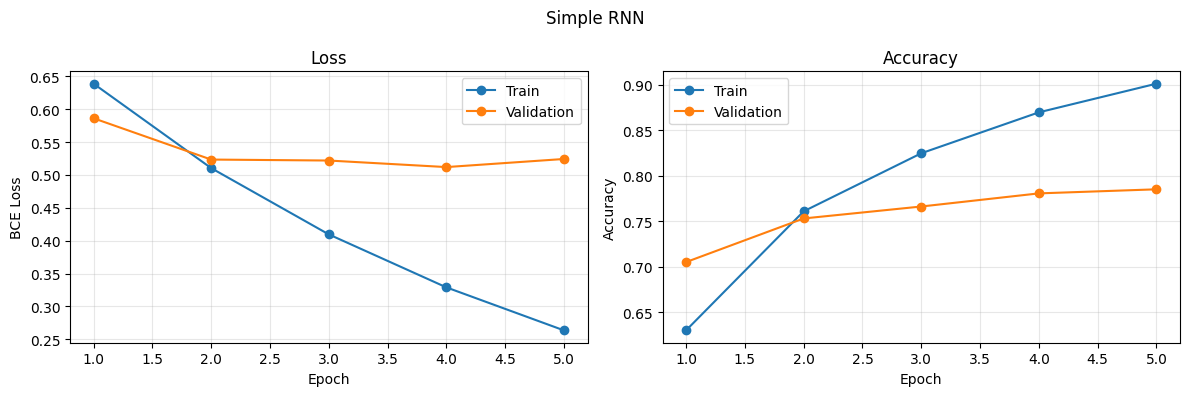

In [19]:
import matplotlib.pyplot as plt
plot_learning_curves(rnn_history, title="Simple RNN")

In [23]:
test_metrics = evaluate_model(rnn_model, test_loader, device)
for name, value in test_metrics.items():
    print(f"   {name:<10}: {value:.4f}")

detailed_test_report(rnn_model, test_loader, device)

   accuracy  : 0.8015
   precision : 0.7959
   recall    : 0.8087
   f1        : 0.8022
Confusion matrix (rows = true, cols = predicted):
[[3943 1020]
 [ 941 3977]]

Classification report:
              precision    recall  f1-score   support

    Negative     0.8073    0.7945    0.8009      4963
    Positive     0.7959    0.8087    0.8022      4918

    accuracy                         0.8015      9881
   macro avg     0.8016    0.8016    0.8015      9881
weighted avg     0.8016    0.8015    0.8015      9881



## Results

| Model | Representation | Accuracy | Precision | Recall | F1 |
|---|---|---:|---:|---:|---:|
| TF-IDF + LR | TF-IDF | **0.8427** | **0.8428** | **0.8427** | **0.8427** |
| RNN | Embedding + RNN | 0.8015 | 0.8016 | 0.8015 | 0.8015 |

TF-IDF + Logistic Regression tốt hơn RNN trên Test Set.

Chênh lệch Accuracy:

```text
0.8427 - 0.8015 = 0.0412
```

Tức là TF-IDF + LR cao hơn RNN khoảng **4.12 điểm phần trăm**.

Chênh lệch F1 cũng tương tự:

```text
0.8427 - 0.8015 = 0.0412
```
RNN có thực sự sử dụng thông tin sequence không?

Chưa chắc đúng còn phải phụ thuộc vào bài toán và dataset


RNN xử lý các từ theo thứ tự:

Thông tin từ `not` có thể được truyền qua hidden state và ảnh hưởng đến các bước sau.

**RNN có khả năng sử dụng thông tin thứ tự mà TF-IDF không biểu diễn trực tiếp**.

---

Kết quả thực nghiệm:

```text
TF-IDF + LR
Test Accuracy = 0.8427
Test F1       = 0.8427

RNN
Test Accuracy = 0.8015
Test F1       = 0.8015
```

Cho thấy:

> Mặc dù RNN có khả năng sử dụng thông tin sequence, trong experiment này khả năng đó **chưa giúp RNN đạt kết quả tốt hơn TF-IDF + Logistic Regression**.

TF-IDF + LR tốt hơn RNN:

> RNN có thực sự sử dụng thông tin sequence mà TF-IDF không sử dụng hay không?

### Trả lời:

**Có về mặt mô hình.**

RNN xử lý các từ theo thứ tự và hidden state lưu thông tin từ các từ trước đó. Vì vậy RNN có khả năng khai thác thông tin sequence, trong khi TF-IDF không biểu diễn thứ tự từ một cách trực tiếp.

Tuy nhiên, **experiment chưa chứng minh rằng thông tin sequence giúp tăng hiệu quả phân loại**.

Cụ thể:

```text
TF-IDF + LR:  F1 = 0.8427
RNN:          F1 = 0.8015
```

Do đó, với dataset và bài toán, **TF-IDF + Logistic Regression cho kết quả tốt hơn Simple RNN**.

# 19. Experiment 4 — RNN vs LSTM vs GRU

## Initial model

In [26]:
class LSTMModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.lstm = nn.LSTM(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )
        self.fc = nn.Linear(hidden_dim, 1)

    def forward(self, x):
        x = self.embedding(x)
        output, (hidden, cell) = self.lstm(x)
        h_last = hidden[-1]
        logits = self.fc(h_last)
        return logits

class GRUModel(nn.Module):
    """GRU Model"""
    def __init__(self, vocab_size, embed_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.gru = nn.GRU(
            input_size=embed_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )
        self.fc = nn.Linear(hidden_dim, 1)
    
    def forward(self, x):
        x = self.embedding(x)
        output, hidden = self.gru(x)
        h_last = hidden[-1]
        logits = self.fc(h_last)
        return logits

## LSTM

In [27]:
if __name__ == "__main__" or "train_df" in globals():
    # Vocabulary comes from TRAIN data only (avoids leakage)
    vocab = build_vocab(train_df, min_freq=MIN_FREQ)
    print("Vocabulary size:", len(vocab))

    train_dataset = SentimentDataset(train_df, vocab)
    val_dataset = SentimentDataset(val_df, vocab)
    test_dataset = SentimentDataset(test_df, vocab)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

    print("\nTraining Configuration:")
    print(f"   Vocabulary size: {len(vocab)}")
    print(f"   Embedding dim:   {EMBED_DIM}")
    print(f"   Hidden dim:      {HIDDEN_DIM}")
    print(f"   Batch size:      {BATCH_SIZE}")
    print(f"   Epochs:          {NUM_EPOCHS}")
    print(f"   Learning rate:   {LEARNING_RATE}")
    print(f"   Device:          {device}")

    rnn_model = RNNClassifier(
        vocab_size=len(vocab),
        embed_dim=EMBED_DIM,
        hidden_dim=HIDDEN_DIM,
        rnn_type="lstm",          # try "lstm" or "gru" to compare
    )

    total_params = sum(p.numel() for p in rnn_model.parameters())
    print(f"\nModel Summary:\n   Total parameters: {total_params:,}")

    print("=" * 60)
    print("TRAINING LSTM")
    print("=" * 60)

    rnn_model, rnn_history, rnn_time = train_model(
        rnn_model, train_loader, val_loader, NUM_EPOCHS, LEARNING_RATE, device
    )
    print(f"\nTraining time: {rnn_time:.1f}s")

    print("\nTest results:")
    test_metrics = evaluate_model(rnn_model, test_loader, device)
    for name, value in test_metrics.items():
        print(f"   {name:<10}: {value:.4f}")

Vocabulary size: 113019

Training Configuration:
   Vocabulary size: 113019
   Embedding dim:   100
   Hidden dim:      50
   Batch size:      32
   Epochs:          5
   Learning rate:   0.001
   Device:          cuda

Model Summary:
   Total parameters: 11,332,351
TRAINING SIMPLE RNN
Epoch 1/5 | Train Loss: 0.5847 | Val Loss: 0.4710 | Train Acc: 0.6855 | Val Acc: 0.7921
Epoch 2/5 | Train Loss: 0.3797 | Val Loss: 0.4293 | Train Acc: 0.8415 | Val Acc: 0.8265
Epoch 3/5 | Train Loss: 0.2556 | Val Loss: 0.3953 | Train Acc: 0.9032 | Val Acc: 0.8414
Epoch 4/5 | Train Loss: 0.1668 | Val Loss: 0.4106 | Train Acc: 0.9427 | Val Acc: 0.8592
Epoch 5/5 | Train Loss: 0.1021 | Val Loss: 0.4758 | Train Acc: 0.9665 | Val Acc: 0.8601

Training time: 183.4s

Test results:
   accuracy  : 0.8458
   precision : 0.8020
   recall    : 0.9164
   f1        : 0.8554


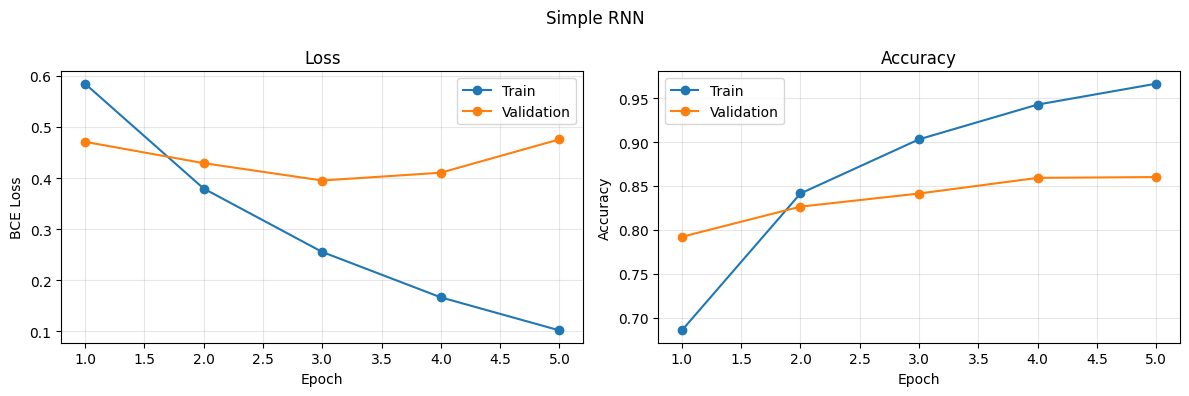

In [28]:
import matplotlib.pyplot as plt
plot_learning_curves(rnn_history, title="Simple RNN")

In [29]:
test_metrics = evaluate_model(rnn_model, test_loader, device)
for name, value in test_metrics.items():
    print(f"   {name:<10}: {value:.4f}")

detailed_test_report(rnn_model, test_loader, device)

   accuracy  : 0.8458
   precision : 0.8020
   recall    : 0.9164
   f1        : 0.8554
Confusion matrix (rows = true, cols = predicted):
[[3850 1113]
 [ 411 4507]]

Classification report:
              precision    recall  f1-score   support

    Negative     0.9035    0.7757    0.8348      4963
    Positive     0.8020    0.9164    0.8554      4918

    accuracy                         0.8458      9881
   macro avg     0.8528    0.8461    0.8451      9881
weighted avg     0.8530    0.8458    0.8450      9881



## GRU

In [30]:
if __name__ == "__main__" or "train_df" in globals():
    # Vocabulary comes from TRAIN data only (avoids leakage)
    vocab = build_vocab(train_df, min_freq=MIN_FREQ)
    print("Vocabulary size:", len(vocab))

    train_dataset = SentimentDataset(train_df, vocab)
    val_dataset = SentimentDataset(val_df, vocab)
    test_dataset = SentimentDataset(test_df, vocab)

    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
    val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)
    test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn)

    print("\nTraining Configuration:")
    print(f"   Vocabulary size: {len(vocab)}")
    print(f"   Embedding dim:   {EMBED_DIM}")
    print(f"   Hidden dim:      {HIDDEN_DIM}")
    print(f"   Batch size:      {BATCH_SIZE}")
    print(f"   Epochs:          {NUM_EPOCHS}")
    print(f"   Learning rate:   {LEARNING_RATE}")
    print(f"   Device:          {device}")

    rnn_model = RNNClassifier(
        vocab_size=len(vocab),
        embed_dim=EMBED_DIM,
        hidden_dim=HIDDEN_DIM,
        rnn_type="gru",          # try "lstm" or "gru" to compare
    )

    total_params = sum(p.numel() for p in rnn_model.parameters())
    print(f"\nModel Summary:\n   Total parameters: {total_params:,}")

    print("=" * 60)
    print("TRAINING GRU")
    print("=" * 60)

    rnn_model, rnn_history, rnn_time = train_model(
        rnn_model, train_loader, val_loader, NUM_EPOCHS, LEARNING_RATE, device
    )
    print(f"\nTraining time: {rnn_time:.1f}s")

    print("\nTest results:")
    test_metrics = evaluate_model(rnn_model, test_loader, device)
    for name, value in test_metrics.items():
        print(f"   {name:<10}: {value:.4f}")

Vocabulary size: 113019

Training Configuration:
   Vocabulary size: 113019
   Embedding dim:   100
   Hidden dim:      50
   Batch size:      32
   Epochs:          5
   Learning rate:   0.001
   Device:          cuda

Model Summary:
   Total parameters: 11,324,751
TRAINING LSTM
Epoch 1/5 | Train Loss: 0.5811 | Val Loss: 0.4782 | Train Acc: 0.6852 | Val Acc: 0.7856
Epoch 2/5 | Train Loss: 0.3482 | Val Loss: 0.3478 | Train Acc: 0.8559 | Val Acc: 0.8526
Epoch 3/5 | Train Loss: 0.1986 | Val Loss: 0.3216 | Train Acc: 0.9274 | Val Acc: 0.8767
Epoch 4/5 | Train Loss: 0.1067 | Val Loss: 0.3572 | Train Acc: 0.9649 | Val Acc: 0.8695
Epoch 5/5 | Train Loss: 0.0492 | Val Loss: 0.4484 | Train Acc: 0.9850 | Val Acc: 0.8686

Training time: 183.5s

Test results:
   accuracy  : 0.8761
   precision : 0.8700
   recall    : 0.8831
   f1        : 0.8765


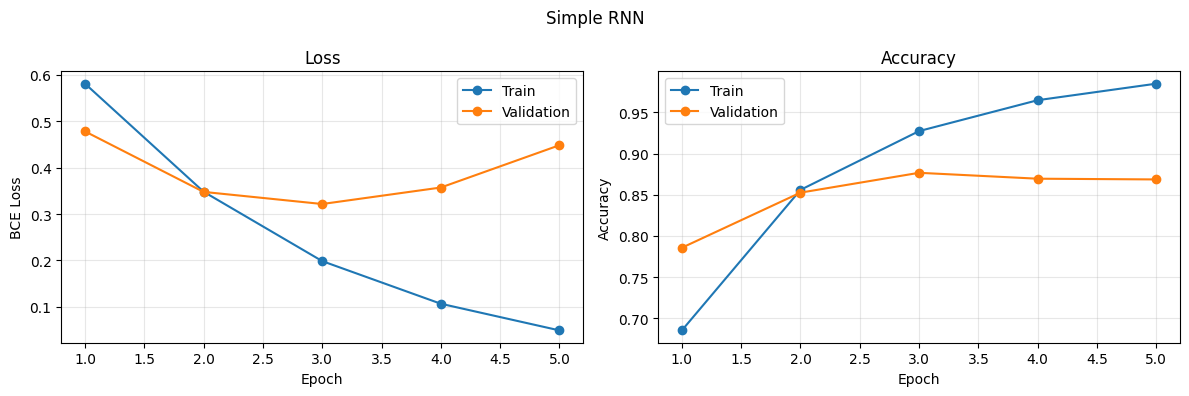

In [31]:
import matplotlib.pyplot as plt
plot_learning_curves(rnn_history, title="GRU")

In [32]:
test_metrics = evaluate_model(rnn_model, test_loader, device)
for name, value in test_metrics.items():
    print(f"   {name:<10}: {value:.4f}")

detailed_test_report(rnn_model, test_loader, device)

   accuracy  : 0.8761
   precision : 0.8700
   recall    : 0.8831
   f1        : 0.8765
Confusion matrix (rows = true, cols = predicted):
[[4314  649]
 [ 575 4343]]

Classification report:
              precision    recall  f1-score   support

    Negative     0.8824    0.8692    0.8758      4963
    Positive     0.8700    0.8831    0.8765      4918

    accuracy                         0.8761      9881
   macro avg     0.8762    0.8762    0.8761      9881
weighted avg     0.8762    0.8761    0.8761      9881



## Result


### Prediction ban đầu

Trước experiment, prediction là:

> LSTM và GRU có thể đạt kết quả tốt hơn Simple RNN vì chúng có cơ chế gate giúp kiểm soát và duy trì thông tin tốt hơn trong sequence.

Đặc biệt:

- Simple RNN dễ gặp vấn đề vanishing gradient.
- LSTM sử dụng cell state và các gate để duy trì thông tin dài hạn.
- GRU sử dụng update gate và reset gate với kiến trúc đơn giản hơn LSTM.

---

### Kết quả thực nghiệm

| Model | Parameters | Training time | Accuracy | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|---:|
| RNN | 11,309,551 | 181.9 s | 0.8015 | 0.7959 | 0.8087 | 0.8015 |
| LSTM | 11,332,351 | 183.4s | **0.8458** | 0.8020 | **0.9164** | 0.8554 |
| GRU | 11,324,751 | 183.5s | **0.8761** | **0.8700** | 0.8831 | **0.8765** |


### Kết luận: Prediction ban đầu có đúng không?

**Có.**

Kết quả thực nghiệm phù hợp với prediction ban đầu rằng các kiến trúc có cơ chế gate như LSTM và GRU sẽ hoạt động tốt hơn Simple RNN.

Kết quả:

```text
RNN  → F1 = 0.8015
LSTM → F1 = 0.8554
GRU  → F1 = 0.8765
```

> **Prediction ban đầu được hỗ trợ bởi kết quả thực nghiệm. LSTM và GRU đều cải thiện đáng kể so với Simple RNN. Trong ba mô hình, GRU cho kết quả tốt nhất xét theo F1-score, trong khi LSTM có Recall cao nhất. Vì vậy không nên chỉ dựa vào Accuracy; Precision, Recall và đặc biệt F1 cho thấy GRU là lựa chọn tốt nhất trong experiment này.**



# 20. Experiment 5 — Sequence length

Vocabulary size: 113019

max_length = 50 | tokens retained: 21.5% | reviews truncated: 97.5%
--- seed 42 ---
Epoch 1/5 | Train Loss: 0.6907 | Val Loss: 0.6739 | Train Acc: 0.5379 | Val Acc: 0.5885
Epoch 2/5 | Train Loss: 0.6282 | Val Loss: 0.6298 | Train Acc: 0.6588 | Val Acc: 0.6685
Epoch 3/5 | Train Loss: 0.5447 | Val Loss: 0.6359 | Train Acc: 0.7412 | Val Acc: 0.6600
Epoch 4/5 | Train Loss: 0.4546 | Val Loss: 0.6511 | Train Acc: 0.8040 | Val Acc: 0.6996
Epoch 5/5 | Train Loss: 0.3694 | Val Loss: 0.6744 | Train Acc: 0.8525 | Val Acc: 0.6977

max_length = 100 | tokens retained: 41.5% | reviews truncated: 87.8%
--- seed 42 ---
Epoch 1/5 | Train Loss: 0.6935 | Val Loss: 0.6775 | Train Acc: 0.5235 | Val Acc: 0.5728
Epoch 2/5 | Train Loss: 0.6326 | Val Loss: 0.6275 | Train Acc: 0.6546 | Val Acc: 0.6758
Epoch 3/5 | Train Loss: 0.5567 | Val Loss: 0.6120 | Train Acc: 0.7288 | Val Acc: 0.6822
Epoch 4/5 | Train Loss: 0.4720 | Val Loss: 0.6416 | Train Acc: 0.7902 | Val Acc: 0.6659
Epoch 5/5 | T

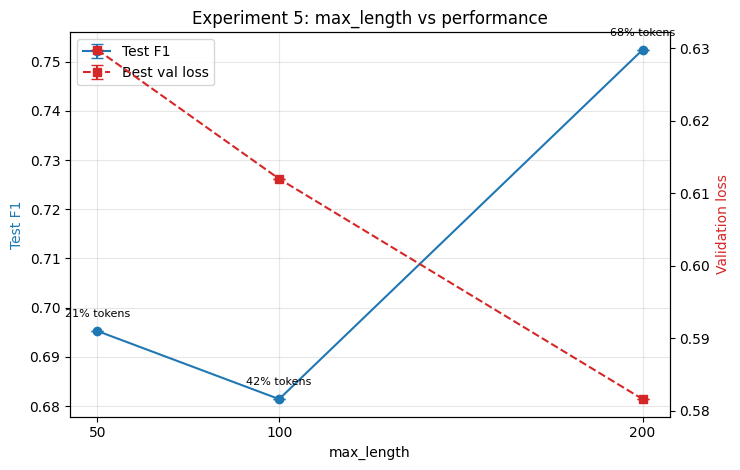

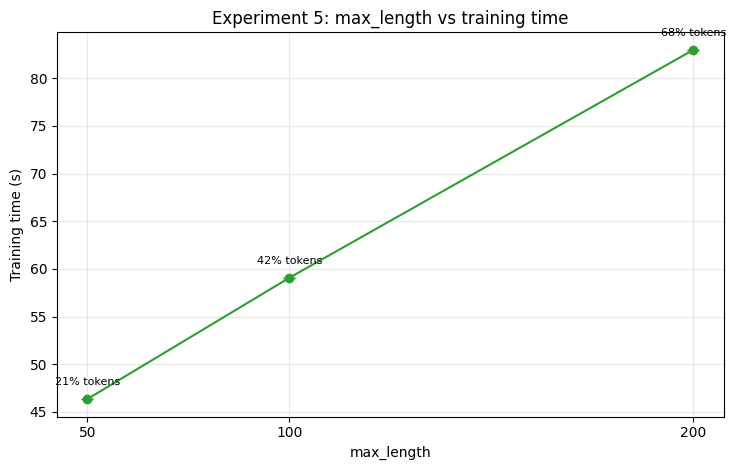

NameError: name 'run_experiment_6' is not defined

In [20]:
import gc
import math
import random
import re
import threading
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader

try:
    import psutil
except ImportError:
    psutil = None

if "RNNClassifier" not in globals():
    from sentiment_rnn_pipeline import *  # noqa: F401,F403

assert all(n in globals() for n in ("train_df", "val_df", "test_df")), \
    "Define train_df, val_df and test_df (with 'words' and 'label' columns) first."

# ======================================================================
# Shared configuration
# ======================================================================
SEEDS = [42]            # repeat each run to get mean +- std (use [42] for a quick test)
TRUNCATE_FROM = "head"          # "head" keeps the first L tokens, "tail" keeps the last L

# Experiment 5
MAX_LENGTHS = [50, 100, 200]

# Experiment 6
MODEL_TYPES = ["rnn"]           # add "lstm", "gru" to compare with gated models
MAX_LEN_EXP6 = 200              # truncation used when training the models for Exp. 6
SEQ_LENGTHS = [20, 50, 100]     # total length of the synthetic sequences
POSITIONS = {"beginning": 0.05, "middle": 0.50, "end": 0.95}
N_SAMPLES = 200                 # synthetic sequences per condition
POS_KEYS = ["excellent", "great", "wonderful", "amazing", "fantastic"]
NEG_KEYS = ["terrible", "awful", "horrible", "boring", "bad"]

# Fixed vocabulary (built once from the training set) so that only
# max_length changes between runs.
vocab = build_vocab(train_df, min_freq=MIN_FREQ)
print("Vocabulary size:", len(vocab))


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


class TruncatedDataset(SentimentDataset):
    """SentimentDataset that keeps at most `max_length` tokens per review."""

    def __init__(self, df, vocab, max_length=None):
        super().__init__(df, vocab)
        self.max_length = max_length

    def __getitem__(self, idx):
        words = self.words[idx]
        if self.max_length is not None:
            words = words[: self.max_length] if TRUNCATE_FROM == "head" else words[-self.max_length:]
        tokens = numericalize(words, self.vocab)
        return (torch.tensor(tokens, dtype=torch.long),
                torch.tensor(self.labels[idx], dtype=torch.float))


def make_loaders(max_length):
    sets = [TruncatedDataset(df, vocab, max_length) for df in (train_df, val_df, test_df)]
    return (
        DataLoader(sets[0], batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn),
        DataLoader(sets[1], batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn),
        DataLoader(sets[2], batch_size=BATCH_SIZE, shuffle=False, collate_fn=collate_fn),
    )


def token_retention(df, max_length):
    """Return (% of tokens kept, % of reviews that get truncated)."""
    lens = np.array([len(w) for w in df["words"]])
    kept = np.minimum(lens, max_length).sum() / lens.sum() * 100
    truncated = (lens > max_length).mean() * 100
    return kept, truncated


class MemoryTracker:
    """Peak GPU memory (torch) and approximate peak CPU RSS increase (psutil)."""

    def __enter__(self):
        gc.collect()
        self.peak_gpu_mb = float("nan")
        self.peak_cpu_mb = float("nan")
        self._stop = False
        if device.type == "cuda":
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
        if psutil is not None:
            self._proc = psutil.Process()
            self._base = self._proc.memory_info().rss
            self.peak_cpu_mb = 0.0
            self._thread = threading.Thread(target=self._poll, daemon=True)
            self._thread.start()
        return self

    def _poll(self):
        while not self._stop:
            delta = (self._proc.memory_info().rss - self._base) / 2**20
            self.peak_cpu_mb = max(self.peak_cpu_mb, delta)
            time.sleep(0.05)

    def __exit__(self, *exc):
        self._stop = True
        if psutil is not None:
            self._thread.join()
        if device.type == "cuda":
            torch.cuda.synchronize()
            self.peak_gpu_mb = torch.cuda.max_memory_allocated() / 2**20


# ======================================================================
# EXPERIMENT 5 - Sequence length
# ======================================================================
def run_experiment_5():
    rows = []
    for L in MAX_LENGTHS:
        kept, truncated = token_retention(train_df, L)
        print(f"\n{'=' * 60}\nmax_length = {L} | tokens retained: {kept:.1f}% "
              f"| reviews truncated: {truncated:.1f}%\n{'=' * 60}")

        for seed in SEEDS:
            set_seed(seed)
            train_loader, val_loader, test_loader = make_loaders(L)
            model = RNNClassifier(len(vocab), EMBED_DIM, HIDDEN_DIM, rnn_type="rnn")

            print(f"--- seed {seed} ---")
            with MemoryTracker() as mem:
                model, hist, train_time = train_model(
                    model, train_loader, val_loader, NUM_EPOCHS, LEARNING_RATE, device
                )
            test_m = evaluate_model(model, test_loader, device)

            rows.append({
                "max_length": L,
                "seed": seed,
                "tokens_retained_pct": kept,
                "reviews_truncated_pct": truncated,
                "train_time_s": train_time,
                "best_val_loss": min(hist["val_loss"]),
                "test_f1": test_m["f1"],
                "test_acc": test_m["accuracy"],
                "peak_gpu_mb": mem.peak_gpu_mb,
                "peak_cpu_rss_delta_mb": mem.peak_cpu_mb,
            })

    results = pd.DataFrame(rows)
    summary = results.groupby("max_length").agg(
        tokens_retained_pct=("tokens_retained_pct", "first"),
        reviews_truncated_pct=("reviews_truncated_pct", "first"),
        train_time_mean=("train_time_s", "mean"),
        train_time_std=("train_time_s", "std"),
        val_loss_mean=("best_val_loss", "mean"),
        val_loss_std=("best_val_loss", "std"),
        f1_mean=("test_f1", "mean"),
        f1_std=("test_f1", "std"),
        peak_gpu_mb=("peak_gpu_mb", "mean"),
        peak_cpu_rss_delta_mb=("peak_cpu_rss_delta_mb", "mean"),
    ).fillna({"train_time_std": 0, "val_loss_std": 0, "f1_std": 0})

    # Marginal return of going from one max_length to the next
    summary["delta_f1"] = summary["f1_mean"].diff()
    summary["delta_time_s"] = summary["train_time_mean"].diff()
    summary["f1_gain_per_extra_second"] = summary["delta_f1"] / summary["delta_time_s"]

    print("\n" + "=" * 60 + "\nEXPERIMENT 5 SUMMARY (mean over seeds)\n" + "=" * 60)
    print(summary.round(4).to_string())
    return results, summary


def plot_experiment_5(summary):
    L = summary.index.values

    # --- Plot 1: max_length -> performance ---
    fig, ax1 = plt.subplots(figsize=(7.5, 4.8))
    ax1.errorbar(L, summary["f1_mean"], yerr=summary["f1_std"], marker="o",
                 capsize=4, color="tab:blue", label="Test F1")
    ax1.set_xlabel("max_length")
    ax1.set_ylabel("Test F1", color="tab:blue")
    ax1.set_xticks(L)
    ax1.grid(True, alpha=0.3)
    for x, y, r in zip(L, summary["f1_mean"], summary["tokens_retained_pct"]):
        ax1.annotate(f"{r:.0f}% tokens", (x, y), textcoords="offset points",
                     xytext=(0, 10), ha="center", fontsize=8)

    ax2 = ax1.twinx()
    ax2.errorbar(L, summary["val_loss_mean"], yerr=summary["val_loss_std"], marker="s",
                 capsize=4, color="tab:red", linestyle="--", label="Best val loss")
    ax2.set_ylabel("Validation loss", color="tab:red")

    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="best")
    ax1.set_title("Experiment 5: max_length vs performance")
    plt.tight_layout()
    plt.show()

    # --- Plot 2: max_length -> training time ---
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    ax.errorbar(L, summary["train_time_mean"], yerr=summary["train_time_std"], marker="o",
                capsize=4, color="tab:green")
    ax.set_xlabel("max_length")
    ax.set_ylabel("Training time (s)")
    ax.set_xticks(L)
    ax.grid(True, alpha=0.3)
    for x, y, r in zip(L, summary["train_time_mean"], summary["tokens_retained_pct"]):
        ax.annotate(f"{r:.0f}% tokens", (x, y), textcoords="offset points",
                    xytext=(0, 10), ha="center", fontsize=8)
    ax.set_title("Experiment 5: max_length vs training time")
    plt.tight_layout()
    plt.show()





# ======================================================================
# Run
# ======================================================================
if __name__ == "__main__":
    results5, summary5 = run_experiment_5()
    plot_experiment_5(summary5)

## Result

### Kết quả thực nghiệm

| max_length | Tokens retained | Reviews truncated | Training time (s) | Val Loss | F1 | Peak GPU (MB) |
|---:|---:|---:|---:|---:|---:|---:|
| 50  | 21.49% | 97.54% | 46.35 | 0.6298 | 0.6953 | 456.60 |
| 100 | 41.52% | 87.76% | 59.07 | 0.6120 | 0.6814 | 456.61 |
| 200 | 68.49% | 40.98% | 82.99 | 0.5816 | **0.7524** | 456.64 |

### Nhận xét

Khi tăng `max_length`:

- `50 → 100`:
  - Token được giữ lại tăng từ **21.49% → 41.52%**.
  - Training time tăng từ **46.35s → 59.07s**.
  - Tuy nhiên F1 giảm từ **0.6953 → 0.6814**.

- `100 → 200`:
  - Token được giữ lại tăng đáng kể lên **68.49%**.
  - Review bị truncate giảm mạnh từ **87.76% → 40.98%**.
  - Training time tăng lên **82.99s**.
  - F1 tăng mạnh lên **0.7524**.
  - Validation loss giảm từ **0.6120 → 0.5816**.

Do đó, `max_length = 200` cho kết quả tốt nhất trong ba cấu hình.

---

### Context và performance

Có thể thấy rõ ảnh hưởng của việc giữ lại nhiều context hơn:

```text
max_length = 50
    ↓
21.5% tokens retained
97.5% reviews truncated
    ↓
F1 = 0.6953
```

```text
max_length = 100
    ↓
41.5% tokens retained
87.8% reviews truncated
    ↓
F1 = 0.6814
```

```text
max_length = 200
    ↓
68.5% tokens retained
41.0% reviews truncated
    ↓
F1 = 0.7524
```

Khi `max_length = 50`, phần lớn review bị cắt bỏ (**97.5%**). Vì vậy, mô hình có thể mất nhiều thông tin quan trọng nằm ở phía sau review.

Khi tăng lên `max_length = 200`, mô hình giữ được khoảng **68.5% số token** và tỷ lệ review bị truncate giảm xuống còn khoảng **41.0%**. Điều này giúp mô hình có nhiều context hơn để đưa ra dự đoán, từ đó F1 tăng lên **0.7524**.

---

### Computational cost

Training time tăng theo `max_length`:

| max_length | Training time |
|---:|---:|
| 50 | 46.35 s |
| 100 | 59.07 s |
| 200 | 82.99 s |

So với `max_length = 50`:

- `max_length = 100` tốn thêm **12.72s**.
- `max_length = 200` tốn thêm **36.64s**.

Đặc biệt, từ `100 → 200`, F1 tăng:

```text
0.6814 → 0.7524
```

tương đương tăng **0.0710 F1**, trong khi training time tăng thêm khoảng **23.92s**.

Điều này cho thấy việc tăng sequence length mang lại lợi ích đáng kể về performance ở khoảng `max_length = 200`.

---

### Memory usage

Peak GPU memory gần như không thay đổi:

```text
max_length = 50   → 456.60 MB
max_length = 100  → 456.61 MB
max_length = 200  → 456.64 MB
```

Chênh lệch chỉ khoảng **0.04 MB**.

Vì vậy, trong thí nghiệm này, thay đổi `max_length` **không tạo ra sự khác biệt đáng kể về peak GPU memory**.

Tuy nhiên, training time vẫn tăng rõ rệt khi sequence dài hơn.

---

### Trade-off giữa context và computational cost

**Có tồn tại trade-off giữa context và computational cost.**

Khi tăng `max_length`, mô hình nhận được nhiều context hơn:

```text
max_length ↑
     ↓
tokens retained ↑
     ↓
information available ↑
     ↓
potential performance ↑
```

Nhưng đồng thời sequence dài hơn làm tăng số bước xử lý của RNN:

```text
max_length ↑
     ↓
sequence length ↑
     ↓
computational cost ↑
     ↓
training time ↑
```

Kết quả thực nghiệm cũng thể hiện điều này:

```text
50  → 46.35s → F1 = 0.6953
100 → 59.07s → F1 = 0.6814
200 → 82.99s → F1 = 0.7524
```

Tuy nhiên, mối quan hệ không hoàn toàn tuyến tính giữa context và performance. Việc tăng `max_length` từ **50 lên 100** làm tăng lượng context nhưng F1 lại giảm. Điều này cho thấy nhiều context hơn **không đảm bảo** performance luôn tăng.

Trong thí nghiệm này, `max_length = 200` là lựa chọn tốt nhất vì nó đạt F1 cao nhất (**0.7524**) và validation loss thấp nhất (**0.5816**), dù training time cao hơn.

---

### Kết luận

> **Có trade-off giữa context và computational cost. Trong thí nghiệm này, `max_length = 200` là lựa chọn phù hợp nhất vì cung cấp nhiều context hơn và đạt F1 cao nhất, mặc dù phải đánh đổi bằng thời gian training lớn hơn.**

## 21. Experiment 6 — Long-range dependency

Positive keywords: ['excellent', 'great', 'wonderful', 'amazing', 'fantastic']
Negative keywords: ['terrible', 'awful', 'horrible', 'boring', 'bad']
Neutral filler pool: 300 words, e.g. ['such', 'do.', 'took', 'desert', 'bank', 'likes', 'professor', 'house', 'join', 'repeated']

=== Training RNN (seed 42) for Experiment 6 ===
Epoch 1/5 | Train Loss: 0.6785 | Val Loss: 0.6520 | Train Acc: 0.5651 | Val Acc: 0.6310
Epoch 2/5 | Train Loss: 0.5952 | Val Loss: 0.6161 | Train Acc: 0.6890 | Val Acc: 0.6794
Epoch 3/5 | Train Loss: 0.5015 | Val Loss: 0.5816 | Train Acc: 0.7662 | Val Acc: 0.7260
Epoch 4/5 | Train Loss: 0.4076 | Val Loss: 0.5876 | Train Acc: 0.8236 | Val Acc: 0.7314
Epoch 5/5 | Train Loss: 0.3281 | Val Loss: 0.5966 | Train Acc: 0.8686 | Val Acc: 0.7502

EXPERIMENT 6A - accuracy of classifying the decisive word
position       beginning  middle    end
model seq_len                          
rnn   20           0.862   0.708  0.722
      50           0.688   0.588  0.653
      100    

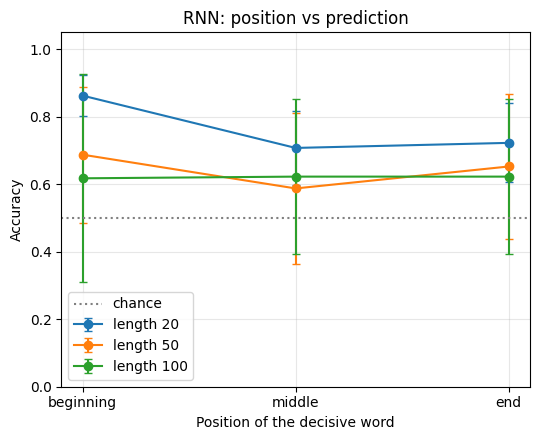

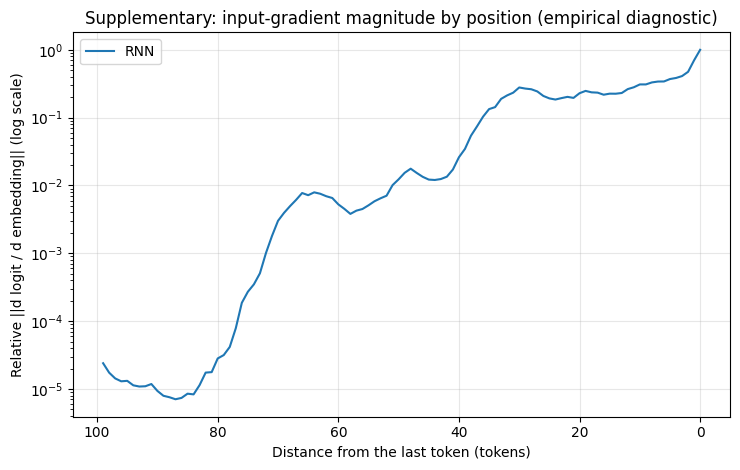

In [22]:
# ======================================================================
# EXPERIMENT 6 - Long-range dependency
# ======================================================================
def simple_tokenize(text):
    # IMPORTANT: make this match the preprocessing that produced df["words"]
    # (lowercasing, punctuation handling, stop-word removal, ...).
    return re.findall(r"[a-z']+", text.lower())


def word_polarity_stats(df, min_count=50):
    """Smoothed log-odds of each vocab word being in a positive vs negative review."""
    pos, neg = Counter(), Counter()
    for words, label in zip(df["words"], df["label"]):
        (pos if label == 1 else neg).update(words)
    n_pos, n_neg, V = sum(pos.values()), sum(neg.values()), len(vocab)
    stats = {}
    for w in vocab:
        if w in (PAD_TOKEN, UNK_TOKEN) or pos[w] + neg[w] < min_count:
            continue
        log_odds = math.log((pos[w] + 1) / (n_pos + V)) - math.log((neg[w] + 1) / (n_neg + V))
        stats[w] = log_odds
    return stats


def select_keywords_and_filler():
    stats = word_polarity_stats(train_df)

    pos_keys = [w for w in POS_KEYS if w in stats and stats[w] > 0]
    neg_keys = [w for w in NEG_KEYS if w in stats and stats[w] < 0]
    ranked = sorted(stats, key=stats.get)
    if len(pos_keys) < 2:      # fallback: most positive words found in the data
        pos_keys = ranked[::-1][:5]
    if len(neg_keys) < 2:      # fallback: most negative words found in the data
        neg_keys = ranked[:5]

    # Neutral filler = frequent words whose polarity is closest to 0
    neutral = sorted(stats, key=lambda w: abs(stats[w]))[:300]
    neutral = [w for w in neutral if w not in pos_keys and w not in neg_keys]

    print("Positive keywords:", pos_keys)
    print("Negative keywords:", neg_keys)
    print(f"Neutral filler pool: {len(neutral)} words, e.g. {neutral[:10]}")
    return pos_keys, neg_keys, neutral


def make_synthetic(key_words, neutral, T, frac, rng, n):
    """n sequences of length T, neutral filler with ONE decisive word at relative position frac."""
    idx = int(round(frac * (T - 1)))
    seqs = []
    for _ in range(n):
        seq = rng.choices(neutral, k=T)
        seq[idx] = rng.choice(key_words)
        seqs.append(seq)
    return seqs


def to_batch(token_lists):
    ids = [torch.tensor(numericalize(t, vocab), dtype=torch.long) for t in token_lists]
    lengths = torch.tensor([len(i) for i in ids], dtype=torch.long)
    x = pad_sequence(ids, batch_first=True, padding_value=PAD_IDX)
    return x.to(device), lengths


@torch.no_grad()
def predict_prob_positive(model, token_lists):
    model.eval()
    x, lengths = to_batch(token_lists)
    return torch.sigmoid(model(x, lengths)).cpu().numpy()


def input_gradient_profile(model, neutral, T=100, n=100):
    """
    Supplementary diagnostic: mean ||d logit / d embedding_t|| for each position t
    on neutral sequences. Purely empirical: it describes how strongly each input
    position influences the output of THIS trained model.
    """
    model.eval()
    rng = random.Random(0)
    x, lengths = to_batch([rng.choices(neutral, k=T) for _ in range(n)])
    store = {}

    def hook(module, inputs, output):
        output.retain_grad()
        store["emb"] = output

    handle = model.embedding.register_forward_hook(hook)
    model.zero_grad()
    with torch.backends.cudnn.flags(enabled=False):   # cuDNN RNN backward needs train mode
        model(x, lengths).sum().backward()
    handle.remove()
    return store["emb"].grad.norm(dim=2).mean(dim=0).cpu().numpy()   # shape (T,)


def run_experiment_6():
    pos_keys, neg_keys, neutral = select_keywords_and_filler()
    conditions = [("positive", pos_keys, 1), ("negative", neg_keys, 0)]

    rows, grad_profiles, custom_rows = [], {}, []

    # Hand-written sentences: decisive word near beginning / middle / end
    templates = {
        "beginning": "{K} , that is the movie , even with many unnecessary scenes and a story that "
                     "kept going for a long time before it ended",
        "middle": "the movie was , despite many unnecessary scenes and a long running time , {K} , "
                  "even though the story kept going for a while",
        "end": "the movie was , despite many unnecessary scenes and a story that kept going for a "
               "long time , ultimately {K}",
    }

    for rnn_type in MODEL_TYPES:
        profiles = []
        for seed in SEEDS:
            print(f"\n=== Training {rnn_type.upper()} (seed {seed}) for Experiment 6 ===")
            set_seed(seed)
            train_loader, val_loader, _ = make_loaders(MAX_LEN_EXP6)
            model = RNNClassifier(len(vocab), EMBED_DIM, HIDDEN_DIM, rnn_type=rnn_type)
            model, _, _ = train_model(model, train_loader, val_loader,
                                      NUM_EPOCHS, LEARNING_RATE, device)

            # --- 6A: controlled synthetic sequences ---
            for T in SEQ_LENGTHS:
                base = predict_prob_positive(
                    model, [random.Random(i).choices(neutral, k=T) for i in range(N_SAMPLES)]
                ).mean()
                for pos_name, frac in POSITIONS.items():
                    for polarity, keys, label in conditions:
                        rng = random.Random(f"{T}-{pos_name}-{polarity}")   # identical data for every model
                        probs = predict_prob_positive(
                            model, make_synthetic(keys, neutral, T, frac, rng, N_SAMPLES)
                        )
                        p_correct = probs if label == 1 else 1 - probs
                        rows.append({
                            "model": rnn_type, "seed": seed, "seq_len": T,
                            "position": pos_name, "polarity": polarity,
                            "p_correct": p_correct.mean(),
                            "accuracy": (p_correct > 0.5).mean(),
                            "baseline_p_pos_no_keyword": base,
                        })

            # --- 6B: hand-written sentences ---
            for pos_name, tpl in templates.items():
                for polarity, key in (("positive", pos_keys[0]), ("negative", neg_keys[0])):
                    p = predict_prob_positive(model, [simple_tokenize(tpl.format(K=key))])[0]
                    custom_rows.append({"model": rnn_type, "seed": seed, "position": pos_name,
                                        "keyword": key, "P(positive)": float(p)})

            # --- 6C: input-gradient profile ---
            profiles.append(input_gradient_profile(model, neutral, T=max(SEQ_LENGTHS)))

        grad_profiles[rnn_type] = np.mean(profiles, axis=0)

    res = pd.DataFrame(rows)
    order = list(POSITIONS)

    summary = (res.groupby(["model", "seq_len", "position"])
                  .agg(accuracy=("accuracy", "mean"), accuracy_std=("accuracy", "std"),
                       p_correct=("p_correct", "mean"))
                  .fillna(0).reset_index())

    print("\n" + "=" * 60 + "\nEXPERIMENT 6A - accuracy of classifying the decisive word\n" + "=" * 60)
    print(summary.pivot_table(index=["model", "seq_len"], columns="position",
                              values="accuracy")[order].round(3).to_string())

    print("\nBy polarity (a model biased towards one class can look fine on average):")
    print(res.pivot_table(index=["model", "seq_len", "polarity"], columns="position",
                          values="p_correct")[order].round(3).to_string())

    print("\nBaseline P(positive) on all-neutral sequences (the model's default lean):")
    print(res.groupby(["model", "seq_len"])["baseline_p_pos_no_keyword"].mean().round(3).to_string())

    print("\n" + "=" * 60 + "\nEXPERIMENT 6B - hand-written sentences (mean P(positive))\n" + "=" * 60)
    custom = pd.DataFrame(custom_rows)
    print(custom.pivot_table(index=["model", "keyword"], columns="position",
                             values="P(positive)")[order].round(3).to_string())

    print(
        "\nREMINDER: these are EMPIRICAL OBSERVATIONS about specific trained models on "
        "synthetic / hand-written inputs.\nThey do not by themselves explain WHY a position "
        "matters, and they do not prove vanishing gradients.\nA theoretical explanation "
        "(repeated Jacobian products through tanh) is a separate argument that these results "
        "can only be consistent or inconsistent with."
    )
    return res, summary, custom, grad_profiles


def plot_experiment_6(summary, grad_profiles):
    order = list(POSITIONS)
    models = summary["model"].unique()

    # --- 6A: accuracy vs position of the decisive word ---
    fig, axes = plt.subplots(1, len(models), figsize=(5.5 * len(models), 4.5), squeeze=False)
    for ax, m in zip(axes[0], models):
        for T in SEQ_LENGTHS:
            sub = summary[(summary["model"] == m) & (summary["seq_len"] == T)].set_index("position").loc[order]
            ax.errorbar(range(len(order)), sub["accuracy"], yerr=sub["accuracy_std"],
                        marker="o", capsize=3, label=f"length {T}")
        ax.axhline(0.5, color="gray", linestyle=":", label="chance")
        ax.set_xticks(range(len(order)))
        ax.set_xticklabels(order)
        ax.set_ylim(0, 1.05)
        ax.set_xlabel("Position of the decisive word")
        ax.set_ylabel("Accuracy")
        ax.set_title(f"{m.upper()}: position vs prediction")
        ax.grid(True, alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()

    # --- 6C: input-gradient norm vs distance from the last token ---
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    for m, prof in grad_profiles.items():
        distance = np.arange(len(prof))[::-1]           # 0 = last token
        ax.plot(distance, prof / (prof.max() + 1e-12), label=m.upper())
    ax.set_yscale("log")
    ax.invert_xaxis()
    ax.set_xlabel("Distance from the last token (tokens)")
    ax.set_ylabel("Relative ||d logit / d embedding|| (log scale)")
    ax.set_title("Supplementary: input-gradient magnitude by position (empirical diagnostic)")
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    results6, summary6, custom6, grad_profiles6 = run_experiment_6()
    plot_experiment_6(summary6, grad_profiles6)

## Result

### Thiết lập thực nghiệm

Mô hình sử dụng là **Simple RNN** với seed = 42.

Kết quả training:

| Epoch | Train Loss | Val Loss | Train Acc | Val Acc |
|---:|---:|---:|---:|---:|
| 1 | 0.6785 | 0.6520 | 0.5651 | 0.6310 |
| 2 | 0.5952 | 0.6161 | 0.6890 | 0.6794 |
| 3 | 0.5015 | 0.5816 | 0.7662 | 0.7260 |
| 4 | 0.4076 | 0.5876 | 0.8236 | 0.7314 |
| 5 | 0.3281 | 0.5966 | 0.8686 | 0.7502 |

---

### Khả năng nhận diện từ quyết định

Accuracy của RNN khi từ mang sentiment xuất hiện ở các vị trí khác nhau:

| Sequence length | Beginning | Middle | End |
|---:|---:|---:|---:|
| 20 | **0.862** | 0.708 | 0.722 |
| 50 | **0.688** | 0.588 | 0.653 |
| 100 | 0.617 | 0.622 | 0.622 |

### Nhận xét

#### Sequence length = 20

Từ quyết định ở đầu sequence có accuracy cao nhất:

```text
Beginning = 0.862
Middle    = 0.708
End       = 0.722
```

Điều này cho thấy trong thí nghiệm này, RNN nhận diện thông tin quyết định tốt nhất khi thông tin xuất hiện ở đầu sequence.

#### Sequence length = 50

Accuracy giảm ở cả ba vị trí:

```text
Beginning = 0.688
Middle    = 0.588
End       = 0.653
```

Đáng chú ý, vị trí middle có kết quả thấp nhất.

#### Sequence length = 100

Accuracy tiếp tục giảm:

```text
Beginning = 0.617
Middle    = 0.622
End       = 0.622
```

Các vị trí trở nên khá tương đương nhau và đều thấp hơn đáng kể so với sequence length = 20.

---

### Phân tích theo polarity

Chỉ nhìn accuracy tổng thể có thể gây hiểu nhầm nếu model có xu hướng dự đoán một class nhiều hơn.

Do đó, thí nghiệm tiếp tục phân tích riêng positive và negative.

#### Sequence length = 20

| Polarity | Beginning | Middle | End |
|---|---:|---:|---:|
| Negative | 0.702 | 0.575 | 0.601 |
| Positive | **0.786** | 0.703 | 0.740 |

Model nhận diện positive tốt hơn negative ở cả ba vị trí.

Đặc biệt, với positive keyword ở beginning:

```text
Positive = 0.786
Negative = 0.702
```

---

#### Sequence length = 50

| Polarity | Beginning | Middle | End |
|---|---:|---:|---:|
| Negative | 0.523 | 0.451 | 0.521 |
| Positive | **0.737** | 0.670 | 0.732 |

Ở sequence length = 50, khả năng nhận diện negative giảm đáng kể, đặc biệt ở vị trí middle:

```text
Negative + Middle = 0.451
```

Trong khi positive vẫn có accuracy tương đối cao:

```text
Positive + Beginning = 0.737
Positive + End       = 0.732
```

---

#### Sequence length = 100

| Polarity | Beginning | Middle | End |
|---|---:|---:|---:|
| Negative | 0.425 | 0.453 | 0.497 |
| Positive | 0.733 | 0.707 | 0.718 |

Ở sequence length = 100, sự khác biệt giữa positive và negative trở nên rất rõ.

Positive vẫn được nhận diện ở mức khoảng 0.71–0.73, trong khi negative chỉ đạt khoảng 0.43–0.50.

Điều này cho thấy accuracy tổng thể cần được diễn giải cùng với **polarity-specific accuracy**.

---

### Kiểm tra bias của model

Để kiểm tra xem model có xu hướng nghiêng về positive hay không, ta đưa vào các sequence chỉ chứa từ trung tính.

Xác suất positive trung bình:

| Sequence length | P(positive) |
|---:|---:|
| 20 | 0.578 |
| 50 | 0.646 |
| 100 | 0.635 |

Các giá trị đều lớn hơn 0.5.

Điều này cho thấy model có một mức **positive bias** nhất định trên các sequence trung tính.

Đặc biệt:

```text
max_length = 50 → P(positive) = 0.646
max_length = 100 → P(positive) = 0.635
```

Vì vậy, một phần kết quả accuracy thấp của negative có thể liên quan đến xu hướng model dự đoán positive.

Do đó, không nên chỉ nhìn accuracy trung bình để kết luận về khả năng ghi nhớ thông tin của RNN.

---

### Experiment 6B — Các câu viết tay

Một số câu được xây dựng với keyword sentiment rõ ràng ở các vị trí khác nhau.

#### Positive keyword: `excellent`

| Position | Mean P(positive) |
|---|---:|
| Beginning | **0.816** |
| Middle | 0.698 |
| End | 0.747 |

#### Negative keyword: `terrible`

| Position | Mean P(positive) |
|---|---:|
| Beginning | 0.181 |
| Middle | 0.203 |
| End | **0.128** |

##### Nhận xét

Với từ `excellent`, xác suất positive cao nhất khi từ này nằm ở beginning:

```text
Beginning = 0.816
Middle    = 0.698
End       = 0.747
```

Với từ `terrible`, xác suất positive thấp nhất khi từ nằm ở end:

```text
Beginning = 0.181
Middle    = 0.203
End       = 0.128
```

Như vậy, các câu viết tay cũng cho thấy **vị trí của keyword có thể ảnh hưởng đến prediction**, nhưng pattern không hoàn toàn giống nhau giữa positive và negative.

---

### Empirical observation

Từ các kết quả trên, ta có thể đưa ra những nhận xét thực nghiệm sau:

1. Vị trí của từ mang sentiment có ảnh hưởng đến prediction của RNN.
2. Với sequence ngắn (`length = 20`), keyword ở beginning cho accuracy cao nhất.
3. Khi sequence dài hơn, accuracy nhìn chung giảm.
4. Model có xu hướng dự đoán positive trên sequence trung tính.
5. Khả năng nhận diện positive và negative không hoàn toàn đối xứng.
6. Với câu viết tay, thay đổi vị trí của keyword cũng làm thay đổi xác suất prediction.

Đây là các **empirical observations**, tức là những gì trực tiếp quan sát được từ model sau khi chạy thí nghiệm.

---

### Result

```text
Vị trí thông tin
      ↓
Prediction thay đổi
      ↓
Empirical observation
      ↓
Có thể phù hợp với vấn đề ghi nhớ thông tin dài hạn
      ↓
Vanishing gradient là một theoretical explanation
      ↓
Không thể nói experiment này tự nó chứng minh vanishing gradient
```
